# EDA: Propensión de contratación de depósito a plazo

Pregunta de negocio: ¿qué clientes tienen mayor probabilidad de contratar un depósito a plazo, para priorizar
a quién llamar cuando el presupuesto es limitado?.

Datos: Bank Marketing (UCI), archivo `bank-additional-full`.
Son 41.188 contactos de campañas de un banco portugués entre 2008 y 2010, en orden cronológico.
La tasa de conversión global es 11,27%.

Cómo se lee: cada pregunta parte de una hipótesis escrita antes de ver el resultado. Las consultas están
en `sql/02_eda_queries.sql` y se ejecutan con `run(Q['Pxx'])`.
El resumen de veredictos está en `docs/decisiones.md`.

In [1]:
import sys
sys.path.append('..')

from src.bq_utils import load_queries, run

Q = load_queries()
list(Q)

['P1a',
 'P1b',
 'P1c',
 'P2',
 'P3',
 'P4a',
 'P4b',
 'P5a',
 'P5b',
 'P5c',
 'P6',
 'P6b',
 'P7',
 'P8a',
 'P8b',
 'P9',
 'P10',
 'P11',
 'P12a',
 'P12b',
 'P13',
 'P14',
 'P15',
 'P16']

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style='whitegrid', 
    rc={'figure.figsize': (8, 4)}
)
BASE = 0.1127

## Bloque 0. Calidad y Estructura

Antes de buscar patrones se revisan duplicados, nulos, rangos y valores desconocidos.

### P1a. Duplicados
Hipótesis: existen filas duplicadas.
Resultado: 41.188 filas totales y 41.176 distintas, es decir 12 duplicados (0,03%).
Veredicto: confirmada. Se eliminan antes de separar los datos (D12).

In [3]:
df = run(Q['P1a'])
df

,filas_totales,filas_distintas
0,41188,41176


### P1b. Nulos
Resultado: ninguna columna tiene nulos. Los datos faltantes vienen codificados como `unknown` (ver P2).

In [4]:
df = run(Q['P1b'])
df

,age_nulos,job_nulos,marital_nulos,education_nulos,default_credit_nulos,housing_nulos,loan_nulos,contact_nulos,month_nulos,day_of_week_nulos,...,campaign_nulos,pdays_nulos,previous_nulos,poutcome_nulos,emp_var_rate_nulos,cons_price_idx_nulos,cons_conf_idx_nulos,euribor3m_nulos,nr_employed_nulos,y_nulos
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### P1c. Rangos
Resultado: edad de 17 a 98, `campaign` de 1 a 56 y `euribor3m` de 0,634 a 5,045.
Lectura: no hay valores imposibles. El máximo de `campaign` es atípico, y por eso P10 agrupa desde 7 intentos.

In [5]:
df = run(Q['P1c'])
df

,edad_min,edad_max,campaign_min,campaign_max,euribor_min,euribor_max
0,17,98,1,56,0.634,5.045


### P2. Valores `unknown`
Hipótesis: `default_credit` es la variable con más valores `unknown`.
Resultado: `default_credit` 20,9%, `education` 4,2%, `housing` y `loan` 2,4%, `job` 0,8% y `marital` 0,2%.
Veredicto: confirmada. `unknown` se mantiene como categoría propia (D13).

In [6]:
df = run(Q['P2'])
df

,variable,pct_unknown
0,default_credit,0.2087
1,education,0.0420
2,housing,0.0240
3,loan,0.0240
4,job,0.0080
5,marital,0.0019


### P3. Tasa de conversión global
Resultado: 4.640 contrataciones de 41.188 contactos, es decir 11,27%.
Lectura: es la referencia para leer todo lo que sigue. Un modelo que dijera "nadie contrata" acertaría 88,7% y no serviría.

In [7]:
df = run(Q['P3'])
df

,total_contactos,total_contrataciones,tasa_conversion
0,41188,4640,0.1127


## Bloque 1. Perfil del cliente

Quién es el cliente que contrata: ocupación, educación, estado civil, edad y créditos.

### P4a. Ocupaciones de interés
Hipótesis: `housemaid`, `student` y `unemployed` convierten más que el resto.
Resultado: 17,8% (n=2.949) contra 10,8% (n=38.239).
Veredicto: parcial. Lo explica `student`, como se ve en P4b.

In [8]:
df = run(Q['P4a'])
df

,grupo,n,tasa_conversion
0,grupo_H4,2949,0.1780
1,resto,38239,0.1076


### P4b. Cada ocupación por separado
Resultado: `student` 31,4% (n=875), `retired` 25,2% (n=1.720), `unemployed` 14,2%, `admin.` 13,0%,
`housemaid` 10,0% y `blue-collar` 6,9% (n=9.254), la más baja.
Lectura: sin `student`, `housemaid` y `unemployed` quedan cerca del 12%. Los jubilados convierten mucho más
que el promedio.

In [9]:
df = run(Q['P4b'])
df

,job,n,tasa_conversion
0,student,875,0.3143
1,retired,1720,0.2523
2,unemployed,1014,0.1420
3,admin.,10422,0.1297
4,management,2924,0.1122
5,unknown,330,0.1121
6,technician,6743,0.1083
7,self-employed,1421,0.1049
8,housemaid,1060,0.1000
9,entrepreneur,1456,0.0852


### P5a. Educación
Hipótesis: educación baja convierte más que media y alta.
Resultado: `basic.4y` 10,3%, `basic.6y` 8,2%, `basic.9y` 7,8% y `university.degree` 13,7%. `illiterate` (22,2%) tiene solo 18 casos y no se interpreta.
Veredicto: refutada. Ocurre lo contrario.

In [10]:
df = run(Q['P5a'])
df

,education,n,tasa_conversion
0,illiterate,18,0.2222
1,unknown,1731,0.1450
2,university.degree,12168,0.1372
3,professional.course,5243,0.1135
4,high.school,9515,0.1084
5,basic.4y,4176,0.1025
6,basic.6y,2292,0.0820
7,basic.9y,6045,0.0782


### P5b. Estado civil
Hipótesis: `married` convierte más que `single` y `divorced`.
Resultado: `single` 14,0%, `divorced` 10,3% y `married` 10,2%.
Veredicto: refutada. P6b muestra que la ventaja de `single` depende de la edad.

In [11]:
df = run(Q['P5b'])
df

,marital,n,tasa_conversion
0,unknown,80,0.1500
1,single,11568,0.1400
2,divorced,4612,0.1032
3,married,24928,0.1016


### P5c. Ocupación y educación
Resultado: cruce de ambas variables, solo celdas con al menos 100 casos.
Lectura: el orden de las ocupaciones se mantiene en casi todos los niveles de educación, con `student` y `retired` arriba y `blue-collar` abajo (5% a 11%). La educación sola no explica la diferencia.

In [12]:
df = run(Q['P5c'])
df

,job,education,n,tasa_conversion
0,student,unknown,167,0.3533
1,student,high.school,357,0.3193
2,retired,basic.4y,597,0.3099
3,retired,professional.course,241,0.2365
4,retired,university.degree,285,0.2316
5,retired,high.school,276,0.2246
6,student,university.degree,170,0.2059
7,management,unknown,123,0.1626
8,admin.,unknown,249,0.1526
9,services,university.degree,173,0.1503


### P6. Edad
Hipótesis: a mayor edad, menor conversión (incluidos los `retired`).
Resultado: menores de 25, 24,0% (n=1.068). De 25 a 34, 12,2%. De 35 a 54, 8,65%. De 55 a 64, 13,6%. Mayores de 65, 47,2% (n=663).
Veredicto: refutada. La relación tiene forma de U.

In [13]:
df = run(Q['P6'])
df

,tramo_edad,n,tasa_conversion
0,1_<25,1068,0.2397
1,2_25-34,13686,0.1217
2,3_35-44,13500,0.0865
3,4_45-54,8704,0.0865
4,5_55-64,3567,0.1357
5,6_65+,663,0.4721


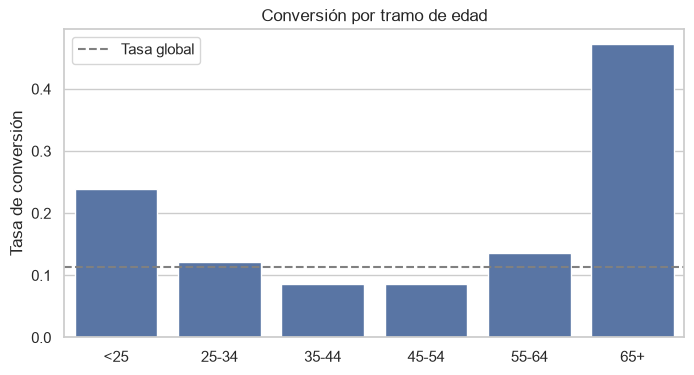

In [14]:
d = run(Q['P6'])
ax = sns.barplot(
    d,
    x='tramo_edad',
    y='tasa_conversion',
    color='C0'
)
ax.axhline(
    BASE,
    color='gray',
    ls='--',
    label='Tasa global'
)
ax.set_xticks(range(len(d)), labels=d.tramo_edad.str[2:])
ax.set(
    title='Conversión por tramo de edad',
    xlabel='',
    ylabel='Tasa de conversión'
)
ax.legend()

# Para guardar la imagen del gráfico generado.
plt.savefig(
    "../reports/figures/edad_u.png",
    dpi=150,
    bbox_inches='tight'
)

plt.show()

La conversión es mínima entre 35 y 54 años y sube en ambos extremos. Los extremos coinciden con estudiantes y jubilados (P4b), así que edad y ocupación no se pueden leer por separado. El tramo de 65 años o más tiene solo 663 casos.

### P6b. Edad y estado civil
Resultado: en menores de 35, `single` convierte 16,2% y `married` 9,8%. Entre 35 y 49 las tres categorías quedan entre 8% y 10%. En mayores de 50, `married` y `divorced` rondan 14,5% y `single` 11,9% (n=462).
Lectura: la ventaja de `single` de P5b existe solo en menores de 35. Mezclaba el efecto de la edad con el del estado civil.

In [15]:
df = run(Q['P6b'])
df

,tramo_edad,marital,n,tasa_conversion
0,1_<35,divorced,780,0.0821
1,1_<35,married,6341,0.0982
2,1_<35,single,7596,0.1618
3,2_35-49,divorced,2381,0.0848
4,2_35-49,married,12467,0.0808
5,2_35-49,single,3510,0.0957
6,3_50+,divorced,1451,0.1447
7,3_50+,married,6120,0.1474
8,3_50+,single,462,0.1190


### P7. Créditos
Hipótesis: con `housing = yes` o `loan = yes`, menor conversión.
Resultado: todas las combinaciones quedan entre 10,7% y 11,7%.
Veredicto: refutada. El efecto es menor a un punto. Además `housing` y `loan` son `unknown` en las mismas 990 filas, así que corresponden a un solo evento de dato faltante.

In [16]:
df = run(Q['P7'])
df

,housing,loan,n,tasa_conversion
0,no,no,16065,0.1091
1,no,yes,2557,0.1072
2,unknown,unknown,990,0.1081
3,yes,no,17885,0.1173
4,yes,yes,3691,0.1108


## Bloque 2. Dinámica de la campaña

Cuándo, cómo y cuántas veces se llamó al cliente.

### P8a. Mes
Hipótesis: los meses con más llamados tienen mayor conversión.
Resultado: mayo tiene 13.769 llamadas y convierte 6,4%. Abril convierte 20,5%. Octubre, septiembre, marzo y diciembre convierten entre 44% y 51%, con entre 182 y 718 llamadas cada uno.
Veredicto: refutada. Ocurre lo contrario, pero P14 muestra que lo explica el período y no el mes.

In [17]:
df = run(Q['P8a'])
df

,month,n,tasa_conversion
0,may,13769,0.0643
1,jul,7174,0.0905
2,aug,6178,0.1060
3,jun,5318,0.1051
4,nov,4101,0.1014
5,apr,2632,0.2048
6,oct,718,0.4387
7,sep,570,0.4491
8,mar,546,0.5055
9,dec,182,0.4890


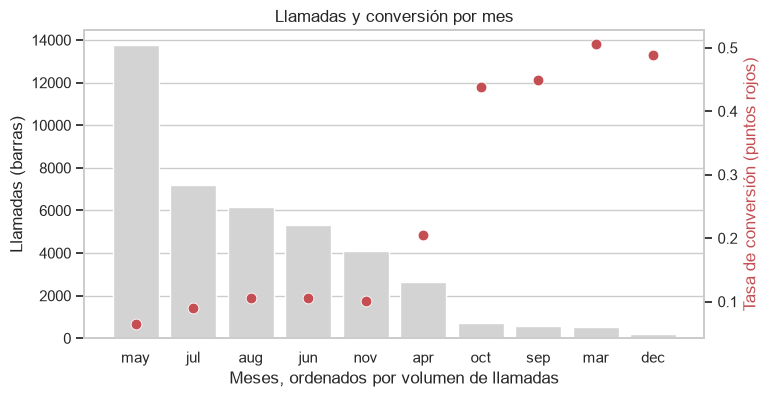

In [18]:
d = run(Q['P8a'])
ax = sns.barplot(
    d,
    x='month',
    y='n',
    color='lightgray'
)
ax2 = ax.twinx()
sns.scatterplot(
    d,
    x='month',
    y='tasa_conversion',
    markers='o',
    color='C3',
    s=60,
    ax=ax2
)
ax.set(
    title='Llamadas y conversión por mes',
    xlabel='Meses, ordenados por volumen de llamadas'
)
ax.set_ylabel('Llamadas (barras)')
ax2.set_ylabel('Tasa de conversión (puntos rojos)', color='C3')
ax2.grid(False)

# Para guardar la imagen del gráfico generado.
plt.savefig(
    "../reports/figures/mes_volumen_tasa.png",
    dpi=150,
    bbox_inches='tight'
)

plt.show()

Los meses con más llamadas convierten menos, y los de alta conversión tienen pocas llamadas. Esta relación no es una propiedad del mes: P14 muestra que esos meses caen casi todos al final del período.

### P8b. Día de la semana
Resultado: va de 9,95% (lunes) a 12,1% (jueves).
Lectura: el efecto es pequeño, de unos dos puntos.

In [19]:
df = run(Q['P8b'])
df

,day_of_week,n,tasa_conversion
0,thu,8623,0.1212
1,mon,8514,0.0995
2,wed,8134,0.1167
3,tue,8090,0.1178
4,fri,7827,0.1081


### P9. Canal
Hipótesis: celular convierte más que teléfono fijo.
Resultado: celular 14,7% (n=26.144) y teléfono fijo 5,2% (n=15.044).
Veredicto: confirmada. P15 muestra que la brecha se reduce al separar por período.

In [20]:
df = run(Q['P9'])
df

,contact,n,tasa_conversion
0,telephone,15044,0.0523
1,cellular,26144,0.1474


### P10. Número de intentos
Hipótesis: la conversión decae después del tercer intento. El valor 7 agrupa "7 o más".
Resultado: 13,0%, 11,5%, 10,8%, 9,4%, 7,5%, 7,7% y 4,6% (7 o más, n=2.406).
Veredicto: confirmada en la dirección, pero la baja es gradual desde el primer intento.

In [21]:
df = run(Q['P10'])
df

,intento,n,tasa_conversion
0,1,17642,0.1304
1,2,10570,0.1146
2,3,5341,0.1075
3,4,2651,0.0939
4,5,1599,0.0750
5,6,979,0.0766
6,7,2406,0.0461


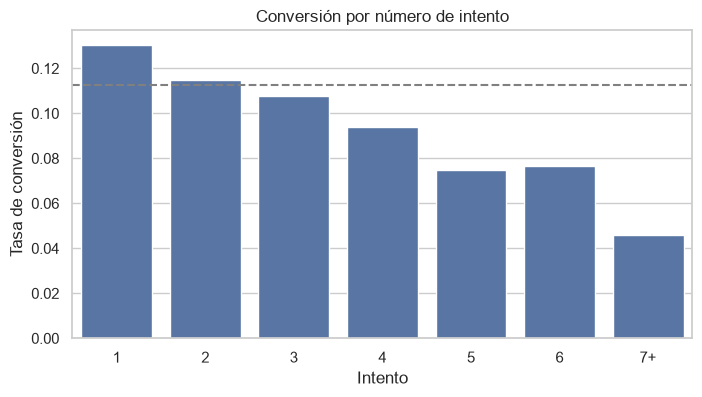

In [22]:
d = run(Q['P10'])
ax = sns.barplot(
    d,
    x='intento',
    y='tasa_conversion',
    color='C0'
)
ax.axhline(BASE, color='gray', ls='--')
ax.set_xticks(range(7), labels=['1', '2', '3', '4', '5', '6', '7+'])
ax.set(
    title='Conversión por número de intento',
    xlabel='Intento',
    ylabel='Tasa de conversión'
)

# Para guardar la imagen del gráfico generado.
plt.savefig(
    "../reports/figures/intentos.png",
    dpi=150,
    bbox_inches='tight'
)

plt.show()

La caída es gradual y no hay un quiebre claro en el tercer intento. Ningún intento queda en cero: el séptimo todavía convierte 4,6%. Además, según la documentación `campaign` incluye el último contacto, así que su uso en el modelo sigue abierto (A3).

## Bloque 3. Historial con el banco

### P11. Resultado de la campaña anterior
Hipótesis: con historial de conversión previo (`poutcome = success`), mayor conversión.
Resultado: `success` 65,1% (n=1.373). `failure` con `pdays` real 51,4% (n=142). `failure` con `pdays = 999` 12,9% (n=4.110). `nonexistent` 8,8% (n=35.563).
Veredicto: confirmada. Es la señal más fuerte del EDA. Incluso quien rechazó antes convierte más que quien nunca fue contactado.
Nota: la consulta separa `historial_previo` (según `previous`) de `ultimo_contacto` (según `pdays`). Los 4.110 casos de `failure` con `pdays = 999` aparecen como contactados antes, sin fecha, como confirma P16.

In [23]:
df = run(Q['P11'])
df

,poutcome,historial_previo,ultimo_contacto,n,tasa_conversion
0,failure,contactado_antes,con_fecha,142,0.5141
1,failure,contactado_antes,sin_fecha,4110,0.1294
2,nonexistent,nunca_contactado,sin_fecha,35563,0.0883
3,success,contactado_antes,con_fecha,1373,0.6511


## Bloque 4. Tiempo y macroeconomía

Los datos están en orden cronológico, así que se revisa cómo cambia la conversión a lo largo del período y cuánto del efecto de otras variables es en realidad efecto del tiempo.

### P12a. Estabilidad en el tiempo
Hipótesis: la conversión no es estable. Entre el bloque más alto y el más bajo hay más de 3 puntos porcentuales.
Resultado: con 10 bloques de unas 4.119 filas en orden cronológico, la conversión va de 2,8% (bloque 1) a 45,9% (bloque 10). El Euribor promedio baja de 4,86 a 0,80.
Veredicto: confirmada, con una diferencia de más de 43 puntos.

In [24]:
df = run(Q['P12a'])
df

,bloque,desde,hasta,n,tasa_conversion,euribor_prom,emp_var_prom,nr_employed_prom
0,1,0,4118,4119,0.0277,4.86,1.10,5191.0
1,2,4119,8237,4119,0.0352,4.86,1.13,5195.0
2,3,8238,12356,4119,0.0422,4.94,1.40,5228.0
3,4,12357,16475,4119,0.0663,4.96,1.40,5228.0
4,5,16476,20594,4119,0.0624,4.96,1.40,5228.0
5,6,20595,24713,4119,0.0546,4.84,1.14,5222.0
6,7,24714,28832,4119,0.1017,3.37,-0.57,5169.0
7,8,28833,32951,4119,0.1197,1.35,-1.80,5099.0
8,9,32952,37069,4118,0.1574,1.26,-2.03,5094.0
9,10,37070,41187,4118,0.4594,0.80,-2.36,5015.0


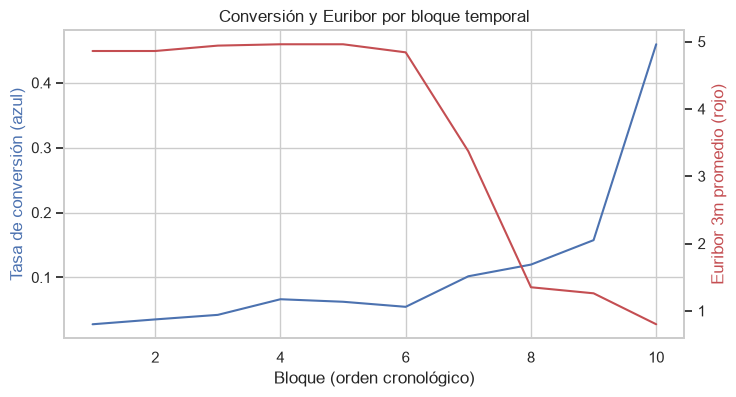

In [25]:
d = run(Q['P12a'])
ax = sns.lineplot(
    d,
    x='bloque',
    y='tasa_conversion',
    markers='o'
)
ax2 = ax.twinx()
sns.lineplot(
    d,
    x='bloque',
    y='euribor_prom',
    markers='s',
    color='C3',
    ax=ax2
)
ax.set(
    title='Conversión y Euribor por bloque temporal',
    xlabel='Bloque (orden cronológico)',
    ylabel='Tasa de conversión'
)
ax.set_ylabel('Tasa de conversión (azul)', color='C0')
ax2.set_ylabel('Euribor 3m promedio (rojo)', color='C3')
ax2.grid(False)

# Para guardar la imagen del gráfico generado.
plt.savefig(
    "../reports/figures/bloques_euribor.png",
    dpi=150,
    bbox_inches='tight'
)

plt.show()

La conversión sube mientras el Euribor cae. Esto condiciona todo el modelado: con un corte temporal 60/20/20 la tasa de positivos sería cercana a 4,8% en train y a 30,8% en test. Por eso las métricas y la calibración deben tolerar ese cambio (A1 y A2).

### P12b. Correlación entre variables macro
Hipótesis: `emp_var_rate`, `euribor3m` y `nr_employed` tienen |r| > 0,8 entre sí.
Resultado: `emp_var_rate` con `euribor3m` 0,972. `emp_var_rate` con `nr_employed` 0,907. `euribor3m` con `nr_employed` 0,945.
Veredicto: confirmada. Se mueven casi en bloque, así que sus coeficientes no se interpretarán por separado y se reportarán resultados con y sin ellas.

In [26]:
df = run(Q['P12b'])
df

,empvar_euribor,empvar_nremp,euribor_nremp,ipc_empvar,confianza_euribor
0,0.972,0.907,0.945,0.775,0.278


### P13. Euribor
Hipótesis: a menor Euribor, menor conversión.
Resultado: con Euribor entre 0 y 1, 45,7% (n=3.890). Entre 1 y 2, 15,9%. Entre 4 y 5, 4,8% (n=27.660). Los tramos 3 y 5 tienen 14 y 16 casos y no se interpretan.
Veredicto: refutada. Ocurre lo contrario, pero coincide con el período (P12a), así que el efecto del Euribor no se puede separar del tiempo.

In [27]:
df = run(Q['P13'])
df

,euribor_tramo,n,tasa_conversion
0,0,3890,0.4571
1,1,9608,0.1585
2,3,14,0.0714
3,4,27660,0.0481
4,5,16,0.5000


### P14. Mes por bloque temporal
Hipótesis: la alta conversión de marzo, septiembre, octubre y diciembre es efecto del período y no del mes.
Resultado: mayo convierte 2,8% en el bloque 1, 3,5% en el 2, 7,7% en el 8, 10,1% en el 9 y 57,6% en el 10. Septiembre cae por completo en el bloque 10, y diciembre casi (172 de 182 llamadas).
Veredicto: confirmada en lo principal. Quedan diferencias dentro de un mismo bloque (en el 9, mayo 10,1% y junio 36,9%), que pueden ser deriva dentro del bloque o un efecto real del mes. Como el mes puede actuar como sustituto del período, es una variable riesgosa para el modelo.

In [28]:
df = run(Q['P14'])
df

,bloque,month,n,tasa_conversion
0,1,may,4119,0.0277
1,2,jun,475,0.0400
2,2,may,3644,0.0346
3,3,jul,220,0.0227
4,3,jun,3899,0.0433
5,4,jul,4119,0.0663
6,5,aug,1773,0.0722
7,5,jul,2346,0.0550
8,6,aug,3402,0.0420
9,6,nov,650,0.0615


### P15. Canal por bloque temporal
Hipótesis: la ventaja del celular se mantiene dentro de cada bloque.
Resultado: los bloques 1 a 3 son solo teléfono fijo. Desde el 4, el celular gana entre 1,3 y 2,8 veces en cada bloque, salvo en el 6 (teléfono fijo 23,5%, n=306).
Veredicto: confirmada con matiz. El canal tiene efecto propio, pero menor que la brecha global de 14,7% contra 5,2%.

In [29]:
df = run(Q['P15'])
df

,bloque,contact,n,tasa_conversion
0,1,telephone,4119,0.0277
1,2,telephone,4119,0.0352
2,3,telephone,4119,0.0422
3,4,cellular,3688,0.0710
4,4,telephone,431,0.0255
5,5,cellular,3755,0.0642
6,5,telephone,364,0.0440
7,6,cellular,3813,0.0401
8,6,telephone,306,0.2353
9,7,cellular,3783,0.1047


### P16. Consistencia entre `poutcome`, `pdays` y `previous`
Hipótesis: `poutcome = failure` con `pdays = 999` corresponde a `previous > 0`.
Resultado: `nonexistent` 35.563 (`pdays = 999`, `previous = 0`). `failure` con `pdays = 999` 4.110 y con `pdays` real 142 (ambos `previous > 0`). `success` 1.373 (`pdays` real, `previous > 0`).
Veredicto: confirmada. Los 4.110 casos sí fueron contactados antes, sin fecha registrada. El valor 999 mezcla "nunca contactado" con "contactado sin fecha". La bandera de contacto previo se construye con `previous > 0` (D14).

In [30]:
df = run(Q['P16'])
df

,poutcome,pdays_flag,previous_flag,n
0,failure,pdays_999,previous > 0,4110
1,failure,pdays_real,previous > 0,142
2,nonexistent,pdays_999,previous = 0,35563
3,success,pdays_real,previous > 0,1373


## Qué cambia para el modelado

- La conversión pasa de 2,8% a 45,9% a lo largo del período. Se usará split temporal y las métricas principales serán ROC-AUC, lift y ganancia acumulada, con PR-AUC junto a la tasa base de cada período. La probabilidad se recalibrará con el conjunto de validación (A1 y A2).
- `duration` queda fuera por leakage (D2).
- Mes y Euribor están confundidos con el período, y las tres variables macro se mueven en bloque. Se reportarán resultados con y sin ellas.
- El historial con el banco es la señal más fuerte. La bandera de contacto previo se construye con `previous > 0` (D14).
- Edad y ocupación están entrelazadas y la relación con la edad no es lineal, lo que favorece modelos de árboles o de gradient boosting.
- Etapa 3: eliminar los 12 duplicados, mantener `unknown` como categoría y decidir el tratamiento de `campaign` (A3).